In [1]:
!nvidia-smi

Sat Nov 21 07:58:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("No GPU detected. Go to Runtime -> Change runtime type -> T4 GPU.")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [2]:
!pip install -q -U "ultralytics[export-litert]" faster-coco-eval

import ultralytics
import torch

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
assert torch.cuda.is_available()

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
typing-inspection 0.4.4 requires typing-extensions>=4.15.0, but you have typing-extensions 4.12.2 which is incompatible.
openai 2.54.0 requires typing-extensions<5,>=4.14, but you have typing-extensions 4.12.2 which is incompatible.
langsmith 0.14.17 requires typing-extensions<5,>=4.14, but you have typing-extensions 4.12.2 which is incompatible.
pydantic 2.14.2 requires typing-extensions>=4.16.0, but you have typing-extensions 4.12.2 which is incompatible.
typeguard 4.6.0 requires typing_extensions>=4.14.0, but you have typing-extensions 4.12.2 which is incompatible.
pydantic-core 2.50.2 requires typing-extensions>=4.16.0, but you have typing-extensions 4.12.2 which is incompatible.
langchain-protocol 0.0.20 requires typing-extensions<5.0.0,>=4.13.0, but you have typing-extensions 4.12.2 which is incompatible.
go

In [4]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

BASE_DRIVE_DIR = Path("/content/drive/MyDrive/PlantCareAI_GPU")
assert BASE_DRIVE_DIR.exists(), f"Base directory not found: {BASE_DRIVE_DIR}"
print("Workspace ready:", BASE_DRIVE_DIR)

Mounted at /content/drive
Workspace ready: /content/drive/MyDrive/PlantCareAI_GPU


In [12]:
import zipfile
import shutil
from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/PlantCareAI_GPU/input/ip102_yolo_fixed.zip")
EXTRACT_DIR = Path("/content/ip102")

assert ZIP_PATH.exists(), f"Dataset ZIP not found at {ZIP_PATH}"

if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)
EXTRACT_DIR.mkdir(parents=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

DATASET_DIR = EXTRACT_DIR / "yolo"

for split in ["train", "val", "test"]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    image_count = len(list(image_dir.glob("*.jpg")))
    label_count = len(list(label_dir.glob("*.txt")))

    print(f"\n{split.upper()}")
    print("Images:", image_count)
    print("Labels:", label_count)

    assert image_count > 0, f"No images found in {image_dir}"
    assert image_count == label_count, f"Image/label count mismatch in {split}!"


TRAIN
Images: 13659
Labels: 13659

VAL
Images: 1518
Labels: 1518

TEST
Images: 3798
Labels: 3798


In [13]:
import re
import yaml

ORIGINAL_YAML = DATASET_DIR / "data.yaml"
COLAB_YAML = DATASET_DIR / "data_colab.yaml"

assert ORIGINAL_YAML.exists(), f"Original YAML not found: {ORIGINAL_YAML}"

yaml_text = ORIGINAL_YAML.read_text(encoding="utf-8")
yaml_text, replacements = re.subn(
    r"(?m)^path\s*:.*$",
    f"path: {DATASET_DIR.as_posix()}",
    yaml_text,
    count=1
)

assert replacements == 1, "Could not update dataset path in data.yaml"
COLAB_YAML.write_text(yaml_text, encoding="utf-8")

with open(COLAB_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print("Dataset path:", config["path"])
print("Number of classes:", len(config["names"]))
print("Class ID range:", min(config["names"]), "-", max(config["names"]))

assert len(config["names"]) == 102
assert min(config["names"]) == 0
assert max(config["names"]) == 101

print("\nYAML verification passed!")

Dataset path: /content/ip102/yolo
Number of classes: 102
Class ID range: 0 - 101

YAML verification passed!


In [14]:
import shutil
from pathlib import Path
from ultralytics import YOLO

BASE_WEIGHTS_DRIVE = Path("/content/drive/MyDrive/PlantCareAI_GPU/input/yolo26n.pt")

# Downloads official COCO-pretrained yolo26n.pt into /content if not already cached
model = YOLO("yolo26n.pt")

# Archive base checkpoint in Google Drive for reproducibility
if not BASE_WEIGHTS_DRIVE.exists() and Path("yolo26n.pt").exists():
    shutil.copy("yolo26n.pt", BASE_WEIGHTS_DRIVE)

model.info()
print("\nBase YOLO26n checkpoint ready:", BASE_WEIGHTS_DRIVE)

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs

Base YOLO26n checkpoint ready: /content/drive/MyDrive/PlantCareAI_GPU/input/yolo26n.pt


In [16]:
import time
import numpy as np
import torch
from ultralytics import YOLO

assert torch.cuda.is_available()

sanity_model = YOLO("yolo26n.pt")
dummy_img = np.zeros((640, 640, 3), dtype=np.uint8)

# Warmup + timed GPU forward pass
_ = sanity_model.predict(dummy_img, imgsz=640, device=0, verbose=False)
t0 = time.perf_counter()
_ = sanity_model.predict(dummy_img, imgsz=640, device=0, verbose=False)
dt_ms = (time.perf_counter() - t0) * 1000

print(f"T4 GPU 640x640 sanity forward pass succeeded in {dt_ms:.2f} ms")

T4 GPU 640x640 sanity forward pass succeeded in 19.14 ms


In [17]:
from pathlib import Path

OUTPUT_DIR = Path("/content/drive/MyDrive/PlantCareAI_GPU/runs/pest")
BASE_RUN_NAME = "ip102_yolo26n_640"

# Automatically find the next available run name to prevent AssertionError
RUN_NAME = BASE_RUN_NAME
RUN_DIR = OUTPUT_DIR / RUN_NAME
counter = 2
while RUN_DIR.exists():
    RUN_NAME = f"{BASE_RUN_NAME}_v{counter}"
    RUN_DIR = OUTPUT_DIR / RUN_NAME
    counter += 1

assert COLAB_YAML.exists(), "data_colab.yaml missing! Run Cell 6 first."

print("Dataset:", COLAB_YAML)
print("Output Directory determined:", RUN_DIR)
print("Ready to train YOLO26n!")

Dataset: /content/ip102/yolo/data_colab.yaml
Output Directory determined: /content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640_v2
Ready to train YOLO26n!


**Experiment B — Train YOLO26n on IP102 at 640px**

In [18]:
import torch
from ultralytics import YOLO

assert torch.cuda.is_available(), "GPU runtime required for training!"

model = YOLO("yolo26n.pt")

results = model.train(
    data=str(COLAB_YAML),

    # Resolution & Batching (uses ~5 GB of 15 GB T4 VRAM; drop batch to 16 if OOM)
    epochs=60,
    imgsz=640,
    batch=32,
    device=0,

    # Optimisation (tuned for fine-tuning 80-class COCO weights onto 102 pest classes)
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.05,
    cos_lr=True,
    momentum=0.9,
    weight_decay=0.0005,
    cls=1.0,                 # Higher classification weight for 102 fine-grained insect species

    # Agricultural / Foliage Augmentations
    degrees=15.0,            # Pests appear at arbitrary orientations on stems and leaves
    flipud=0.5,              # Physically valid for foliage/insect photography
    fliplr=0.5,
    hsv_s=0.6,
    hsv_v=0.4,
    scale=0.5,

    # Training control
    patience=10,
    warmup_epochs=3,
    seed=42,
    close_mosaic=10,

    # GPU and data loading
    workers=2,
    cache=False,
    amp=True,

    # Saving and validation
    save=True,
    save_period=10,
    val=True,
    plots=True,

    # Output
    project=str(OUTPUT_DIR),
    name=RUN_NAME,
    exist_ok=False,
    resume=False,
    verbose=True,

    #Time
    time=2.5,
)

print("\nYOLO26n training completed!")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=1.0, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/ip102/yolo/data_colab.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.9, mosaic=1.0, multi_scale=0.0, name=ip102_yolo26n_640-2, nbs=64, nms=None, opset=None, op

Total epochs recorded: 38
Best checkpoint: /content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2/weights/best.pt

Available columns:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/l1_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/l1_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Top 5 epochs by mAP50-95:
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
    34               0.52669            0.62678           0.59843              0.36928
    37               0.55550            0.61645           0.60181              0.36926
    38               0.58156            0.59463           0.59657              0.36803
    32               0.49034            0.61466           0.59375              0.36770
    35               0.53571            0.62740           0.59937              0.36680

Best checkpoint exists: True
Last checkpoint exists: True


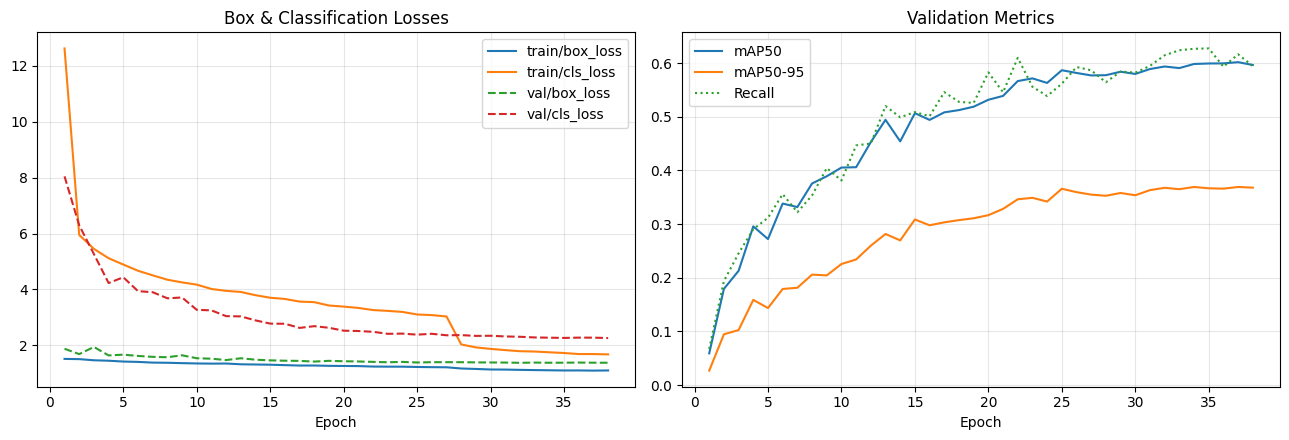

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUN_DIR = Path("/content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2")
RESULTS_CSV = RUN_DIR / "results.csv"
BEST_PT = RUN_DIR / "weights" / "best.pt"
LAST_PT = RUN_DIR / "weights" / "last.pt"

assert RESULTS_CSV.exists(), f"results.csv not found at {RESULTS_CSV}"
assert BEST_PT.exists(), f"best.pt not found at {BEST_PT}"

df = pd.read_csv(RESULTS_CSV)
df.columns = df.columns.str.strip()

print("Total epochs recorded:", len(df))
print("Best checkpoint:", BEST_PT)
print("\nAvailable columns:")
print(df.columns.tolist())

metric_columns = [
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

print("\nTop 5 epochs by mAP50-95:")
print(
    df.nlargest(5, "metrics/mAP50-95(B)")[["epoch"] + metric_columns].to_string(index=False)
)

print("\nBest checkpoint exists:", BEST_PT.exists())
print("Last checkpoint exists:", LAST_PT.exists())

# Plot training curves inline
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(df["epoch"], df["train/box_loss"], label="train/box_loss")
axes[0].plot(df["epoch"], df["train/cls_loss"], label="train/cls_loss")
axes[0].plot(df["epoch"], df["val/box_loss"], "--", label="val/box_loss")
axes[0].plot(df["epoch"], df["val/cls_loss"], "--", label="val/cls_loss")
axes[0].set_title("Box & Classification Losses")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
axes[1].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
axes[1].plot(df["epoch"], df["metrics/recall(B)"], ":", label="Recall")
axes[1].set_title("Validation Metrics")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
from pathlib import Path
from ultralytics import YOLO

# Pointing to the correct directory suffix where training actually saved
BEST_PT = Path("/content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2/weights/best.pt")
COLAB_YAML = Path("/content/ip102/yolo/data_colab.yaml")
TEST_RUN_DIR = "/content/drive/MyDrive/PlantCareAI_GPU/runs/pest"

assert BEST_PT.exists(), f"Best checkpoint not found at {BEST_PT}"
assert COLAB_YAML.exists(), "Colab dataset YAML not found"

model = YOLO(str(BEST_PT))

test_results = model.val(
    data=str(COLAB_YAML),
    split="test",
    imgsz=640,
    batch=32,
    device=0,                # Runs on T4 GPU (~20s instead of ~6m on CPU)
    workers=2,
    plots=True,
    save_json=True,
    project=TEST_RUN_DIR,
    name="ip102_yolo26n_test_640",
    exist_ok=False,
    verbose=True
)

print("\nTEST SET EVALUATION COMPLETED")
print("Precision:", round(float(test_results.box.mp), 5))
print("Recall:", round(float(test_results.box.mr), 5))
print("mAP50:", round(float(test_results.box.map50), 5))
print("mAP50-95:", round(float(test_results.box.map), 5))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,414,278 parameters, 0 gradients, 5.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1185.0±767.7 MB/s, size: 48.7 KB)
val: Scanning /content/ip102/yolo/labels/test... 3798 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3798/3798 1.7Kit/s 2.2s
val: New cache created: /content/ip102/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 119/119 3.1it/s 38.1s
                   all       3798       4444      0.542      0.599      0.574      0.359
      rice leaf roller         35         39      0.708      0.846      0.829       0.57
 rice leaf caterpillar         23         26      0.352      0.308      0.365      0.235
     paddy stem maggot          5          5      0.463        0.6      0.492      0.332
    asiatic rice borer         33         34      0.457      0.706     

In [19]:
import shutil
from pathlib import Path
from ultralytics import YOLO

BEST_PT = Path("/content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2/weights/best.pt")
EXPORT_DIR = Path("/content/drive/MyDrive/PlantCareAI_GPU/exports/yolo26n")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

assert BEST_PT.exists(), f"best.pt not found at {BEST_PT}"
model = YOLO(str(BEST_PT))

# 1. Primary 640x640 w8a32 (~2.9 MB, no calibration needed) -> Exynos 1680 + Snapdragon 665 photo capture
raw_640_w8a32 = model.export(format="litert", imgsz=640, nms=None, quantize="w8a32")
dst_640_w8a32 = EXPORT_DIR / "yolo26n_ip102_640_raw_w8a32.tflite"
shutil.copy(raw_640_w8a32, dst_640_w8a32)

# 2. Fast 416x416 w8a32 (~2.9 MB) -> Snapdragon 665 live viewfinder
raw_416_w8a32 = model.export(format="litert", imgsz=416, nms=None, quantize="w8a32")
dst_416_w8a32 = EXPORT_DIR / "yolo26n_ip102_416_raw_w8a32.tflite"
shutil.copy(raw_416_w8a32, dst_416_w8a32)

# 3. 640x640 FP32 (~10.0 MB) -> Optional for Android GPU OpenCL delegate testing
raw_640_fp32 = model.export(format="litert", imgsz=640, nms=None)
dst_640_fp32 = EXPORT_DIR / "yolo26n_ip102_640_raw_fp32.tflite"
shutil.copy(raw_640_fp32, dst_640_fp32)

print("\nExported models saved to:", EXPORT_DIR)
for f in sorted(EXPORT_DIR.glob("*.tflite")):
    print(f" - {f.name} ({f.stat().st_size / (1024**2):.2f} MB)")

# Sanity-check exported LiteRT tensor shapes
from ai_edge_litert.interpreter import Interpreter
interp = Interpreter(model_path=str(dst_640_w8a32))
interp.allocate_tensors()
print("\nVerified 640 w8a32 Input :", interp.get_input_details()[0]["shape"], interp.get_input_details()[0]["dtype"])
print("Verified 640 w8a32 Output:", interp.get_output_details()[0]["shape"], interp.get_output_details()[0]["dtype"])

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,414,278 parameters, 0 gradients, 5.5 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 106, 8400) (5.3 MB)


W1121 13:43:06.976000 774 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.



LiteRT: starting export with litert_torch 0.10.0...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:03) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

... (72 outputs left out)

(00:14) [ DONE] LiteRT-Torch Convert (+00:14)

(00:00) [START] Write Model to 
/content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2/weights/best.tflite

(00:00) [ DONE] Write Model to 
/content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2/weights/best.tflite (+00:00)

LiteRT: export success ✅ 15.0s, saved as '/content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2/weights/best.tflite' (9.5 MB)

Export complete (15.4s)
Results saved to /content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2/weights/best.tflite
Predict:         yolo predict task=detect model=/content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2/weights/best.tflite imgsz=640 
Validate:        yolo val task=detect model=/content/drive/MyDrive/PlantCareAI_GPU/runs/pest/ip102_yolo26n_640-2/weights/best.tflite imgsz=640 data=/content/ip102/yolo/data_colab.yaml 
Visualize:       https://netron.app

Exported models saved to: /content/drive/MyDrive/PlantCareAI_GPU/exports/yolo26n
 - yolo26n_ip102_416_raw_w8a32.tflite (2.69 MB)
 - yolo26n_ip102_640_raw_fp32.tflite (9.53 MB)
 - yolo26n_ip102_640_raw_w8a32.tflite (2.75 MB)

Verified 640 w8a32 Input : [  1   3 640 640] <class 'numpy.float32'>
Verified 640 w8a32 Output: [   1  106 8400] <class 'numpy.float3